# LifeGuard-RL XJTU state of health estimation

Estimate a cell's capacity-based state of health (SOH) during the charging taper, before the discharge measurement becomes available. Start with two pilot cells, then compare models across all 23 XJTU cells in the fixed 2C and 3C charging groups.

1. Make a private Kaggle dataset containing **XJTU.zip** and **XJTU_labels.json** from the local **Life labels** folder. Import this notebook and attach that dataset as an input. This notebook also accepts a directory with the extracted XJTU pickle files.
2. Run all cells with the default settings for the CPU comparison. Choose **GPU T4 x2** and set **RUN_DUAL_GPU** to **True** to include the 1D CNN on both GPUs.
3. Download **lifeguard_soh_results.zip** from the notebook output after the run. It contains the summary, quality checks, plots, and the model comparison when benchmark mode is enabled.

Set **MODE** to **"pilot"** to run only the data checks and SOH plot for the two recommended cells.

[BatteryLife v12 release](https://zenodo.org/records/21149533) · [Original XJTU study](https://pmc.ncbi.nlm.nih.gov/articles/PMC11109204/) · [Kaggle notebooks](https://www.kaggle.com/docs/notebooks)

In [14]:
# Use "pilot" for the two-cell check or "benchmark" for the 23-cell comparison.
MODE = "benchmark"
RUN_DUAL_GPU = False
INPUT_ROOT = None  # Set a path here if multiple XJTU inputs are attached.
OUTPUT_ROOT = None  # Defaults to /kaggle/working on Kaggle.
SEED = 42

from collections import Counter
from contextlib import nullcontext
from importlib.metadata import version
import json
from pathlib import Path, PurePosixPath
import pickle
import shutil
import subprocess
import sys
from tempfile import TemporaryDirectory
from zipfile import ZIP_DEFLATED, ZipFile

from IPython.display import Image, Markdown, display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import ParameterGrid, StratifiedKFold, StratifiedShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

if MODE not in ("pilot", "benchmark"):
    raise ValueError('Set MODE to "pilot" or "benchmark".')
if RUN_DUAL_GPU and MODE != "benchmark":
    raise ValueError('Set MODE to "benchmark" to train the CNN.')

if INPUT_ROOT is None:
    if Path("/kaggle/input").is_dir():
        INPUT_ROOT = Path("/kaggle/input")
    elif Path.cwd().name == "notebooks":
        INPUT_ROOT = Path.cwd().parent
    else:
        INPUT_ROOT = Path.cwd()
if OUTPUT_ROOT is None:
    OUTPUT_ROOT = Path("/kaggle/working") if Path("/kaggle/working").is_dir() else Path.cwd() / "outputs"
INPUT_ROOT = Path(INPUT_ROOT).resolve()
OUTPUT_ROOT = Path(OUTPUT_ROOT).resolve()
if not INPUT_ROOT.is_dir():
    raise FileNotFoundError(f"Input directory does not exist: {INPUT_ROOT}")

## Data and charging features

The two protocols use the same 2.0 Ah nominal capacity and 1C discharge rate. The target is full-cycle discharge capacity in Ah divided by 2.0 Ah, expressed as a percentage.

Feature extraction stops at the first positive current at or below 0.2 A with voltage at least 4.15 V, following the onset of charging. The features describe the time, voltage rise, and charge accumulated before this cutoff. The full discharge capacity is used to label each cycle. The fixed XJTU files have neither measured temperature nor resistance. Cell IDs and published lifetimes are used for evaluation and quality checks.

In [15]:
PILOT_EOLS = {
    "XJTU_2C_battery-7": 401,
    "XJTU_3C_battery-2": 291,
}
FIXED_CELLS = {
    f"XJTU_{rate}C_battery-{number}": rate
    for rate, count in ((2, 8), (3, 15))
    for number in range(1, count + 1)
}
POINTS = 256
TRACE_COLUMNS = [
    "charge_duration_s",
    "rise_duration_3_8_to_4_0_s",
    "rise_duration_4_0_to_4_1_s",
    "rise_rate_3_8_to_4_1_v_per_s",
    "rise_charge_3_8_to_4_0_ah",
    "rise_charge_4_0_to_4_1_ah",
    "prefix_charge_ah",
    "taper_duration_s",
    "taper_charge_ah",
]
METADATA_COLUMNS = ["cycle", "charge_rate_c"]
CNN_SCALARS = METADATA_COLUMNS + ["charge_duration_s"]


def unique_path(paths, description):
    paths = sorted(set(paths))
    if len(paths) != 1:
        detail = ", ".join(str(path) for path in paths) or "none found"
        raise ValueError(f"Expected one {description}, found {detail}. Set INPUT_ROOT to your dataset directory.")
    return paths[0]


def locate_data(root, cell_ids):
    archives = list(root.rglob("XJTU.zip"))
    if archives:
        archive_path = unique_path(archives, "XJTU.zip")
        with ZipFile(archive_path) as archive:
            members = {}
            for info in archive.infolist():
                name = PurePosixPath(info.filename).stem
                if info.filename.endswith(".pkl") and name in cell_ids:
                    if name in members:
                        raise ValueError(f"Duplicate cell {name} in {archive_path}")
                    members[name] = info
        if missing := sorted(set(cell_ids) - members.keys()):
            raise ValueError(f"Missing expected XJTU members in {archive_path}: {', '.join(missing)}")
        return archive_path, members
    direct = {
        cell_id: unique_path(root.rglob(f"{cell_id}.pkl"), f"file for {cell_id}")
        for cell_id in cell_ids
    }
    return None, direct


class XJTUUnpickler(pickle.Unpickler):
    def find_class(self, module, name):
        raise pickle.UnpicklingError(f"Unexpected global in XJTU data: {module}.{name}")

In [16]:
def charge_prefix(time, voltage, current):
    starts = np.flatnonzero(current > 1.0)
    if not starts.size:
        return None, "no_charge_start"
    start = starts[0]
    i = current[start:]
    v = voltage[start:]
    cutoffs = np.flatnonzero((i > 0.0) & (i <= 0.2) & (v >= 4.15))
    if not cutoffs.size:
        return None, "no_taper_cutoff"
    end = start + cutoffs[0]
    if np.any(current[start:end] <= -0.1):
        return None, "no_taper_cutoff"
    prefix = slice(start, end + 1)
    elapsed = time[prefix] - time[start]
    if len(elapsed) < 2 or np.any(np.diff(elapsed) <= 0):
        return None, "invalid_charge_timestamps"
    return (elapsed, voltage[prefix], current[prefix]), None


def voltage_crossing(level, time, voltage, current, cumulative_ah):
    above = np.flatnonzero(voltage >= level)
    if not above.size or above[0] == 0:
        return None
    hi = above[0]
    lo = hi - 1
    fraction = (level - voltage[lo]) / (voltage[hi] - voltage[lo])
    dt = fraction * (time[hi] - time[lo])
    crossing_current = current[lo] + fraction * (current[hi] - current[lo])
    charge = cumulative_ah[lo] + dt * (current[lo] + crossing_current) / 7200
    return time[lo] + dt, charge


def make_features(prefix):
    time, voltage, current = prefix
    positive_i = np.maximum(current, 0.0)
    delta_ah = np.diff(time) * (positive_i[:-1] + positive_i[1:]) / 7200
    cumulative_ah = np.r_[0.0, np.cumsum(delta_ah)]
    crossings = [
        voltage_crossing(level, time, voltage, positive_i, cumulative_ah)
        for level in (3.8, 4.0, 4.1)
    ]
    if any(crossing is None for crossing in crossings):
        return None, "missing_voltage_crossing"
    (t38, q38), (t40, q40), (t41, q41) = crossings
    if not t38 < t40 < t41:
        return None, "invalid_voltage_crossing_order"
    taper_start = np.flatnonzero((voltage >= 4.15) & (current > 0.0) & (current <= 0.5))[0]
    features = [
        time[-1], t40 - t38, t41 - t40, 0.3 / (t41 - t38), q40 - q38,
        q41 - q40, cumulative_ah[-1], time[-1] - time[taper_start],
        cumulative_ah[-1] - cumulative_ah[taper_start],
    ]
    return dict(zip(TRACE_COLUMNS, features)), None


def resample_curve(prefix):
    time, voltage, current = prefix
    grid = np.linspace(0.0, time[-1], POINTS)
    return np.stack([np.interp(grid, time, signal) for signal in (voltage, current)]).astype(np.float32)

In [17]:
def decode_cell(stream, cell_id, rate, keep_curves):
    battery = XJTUUnpickler(stream).load()
    if battery["cell_id"] != cell_id or battery["nominal_capacity_in_Ah"] != 2.0:
        raise ValueError(f"Unexpected identity or nominal capacity in {cell_id}")
    if [step["rate_in_C"] for step in battery["charge_protocol"]] != [rate]:
        raise ValueError(f"Unexpected charging protocol in {cell_id}")
    if [step["rate_in_C"] for step in battery["discharge_protocol"]] != [1.0]:
        raise ValueError(f"Unexpected discharge protocol in {cell_id}")
    rows, qc, curves = [], [], []
    for cycle in battery["cycle_data"]:
        number = cycle["cycle_number"]
        key = {"cell_id": cell_id, "cycle": number, "charge_rate_c": rate}
        time, voltage, current, discharge = (
            np.asarray(cycle[field], dtype=np.float64)
            for field in ("time_in_s", "voltage_in_V", "current_in_A", "discharge_capacity_in_Ah")
        )
        target_ok = discharge.ndim == 1 and discharge.size > 0 and np.isfinite(discharge).all()
        capacity_ah = float(discharge.max()) if target_ok else np.nan
        soh = 100.0 * capacity_ah / 2.0
        row_qc = {**key, "discharge_capacity_ah": capacity_ah, "soh_pct": soh}
        traces = (time, voltage, current, discharge)
        if any(trace.ndim != 1 or trace.size != time.size for trace in traces) or time.size < 2:
            reason = "unaligned_or_empty_arrays"
        elif not all(np.isfinite(trace).all() for trace in traces):
            reason = "nonfinite_trace"
        elif np.any(np.diff(time) <= 0):
            reason = "nonincreasing_timestamps"
        elif cycle.get("attribute") != "Cycling" or not np.any(current < -0.1) or capacity_ah <= 0:
            reason = "missing_full_discharge"
        else:
            prefix, reason = charge_prefix(time, voltage, current)
            if reason is None:
                features, reason = make_features(prefix)
        qc.append({**row_qc, "status": reason or "ok"})
        if reason is None:
            rows.append({**key, "soh_pct": soh, **features})
            if keep_curves:
                curves.append(resample_curve(prefix))
    cycles = [row["cycle"] for row in qc]
    if not cycles or cycles != list(range(1, len(cycles) + 1)):
        raise ValueError(f"Unexpected cycle numbering in {cell_id}")
    return rows, qc, curves


def load_experiment_data(input_root, cell_ids, keep_curves):
    archive_path, files = locate_data(input_root, cell_ids)
    rows, quality_rows, curves = [], [], []
    with ZipFile(archive_path) if archive_path else nullcontext() as archive:
        for cell_id in cell_ids:
            rate = FIXED_CELLS[cell_id]
            source = archive.open(files[cell_id]) if archive else files[cell_id].open("rb")
            with source as stream:
                new_rows, new_qc, new_curves = decode_cell(stream, cell_id, rate, keep_curves)
            rows.extend(new_rows)
            quality_rows.extend(new_qc)
            curves.extend(new_curves)
            print(f"{cell_id}: {len(new_rows)}/{len(new_qc)} valid cycles")
    if not rows or set(cell_ids) != {row["cell_id"] for row in rows}:
        raise ValueError("Every selected cell must contribute at least one eligible cycle.")
    features = pd.DataFrame(rows)
    quality = pd.DataFrame(quality_rows)
    return features, quality, np.stack(curves) if keep_curves else None


def check_pilot(quality, labels):
    for cell_id, expected_eol in PILOT_EOLS.items():
        cell_quality = quality[quality.cell_id == cell_id]
        crossings = cell_quality.loc[cell_quality.soh_pct <= 80.0, "cycle"]
        published = labels.get(f"{cell_id}.pkl")
        if published != expected_eol or crossings.empty or int(crossings.iloc[0]) != expected_eol:
            raise ValueError(f"{cell_id}: expected a recorded crossing and published label at cycle {expected_eol}.")
        print(f"{cell_id}: verified 80% SOH crossing at cycle {expected_eol}")


def check_charge_cutoff():
    time = np.arange(9, dtype=float)
    voltage = np.array([3.6, 3.8, 3.95, 4.1, 4.16, 4.18, 4.18, 3.9, 2.5])
    current = np.array([4.0, 4.0, 4.0, 4.0, 0.45, 0.3, 0.19, -2.0, -2.0])
    before, error = charge_prefix(time, voltage, current)
    assert error is None
    voltage[7:] = [5.5, 2.6]
    current[7:] = [2.5, 4.8]
    after, error = charge_prefix(time, voltage, current)
    assert error is None
    assert make_features(before) == make_features(after)
    np.testing.assert_array_equal(resample_curve(before), resample_curve(after))
    assert charge_prefix(time[:6], voltage[:6], current[:6])[1] == "no_taper_cutoff"

In [18]:
selected_ids = list(PILOT_EOLS if MODE == "pilot" else FIXED_CELLS)
label_path = unique_path(INPUT_ROOT.rglob("XJTU_labels.json"), "XJTU_labels.json")
labels = json.loads(label_path.read_text(encoding="utf-8"))
check_charge_cutoff()
features, quality, charge_curves = load_experiment_data(INPUT_ROOT, selected_ids, RUN_DUAL_GPU)
check_pilot(quality, labels)
print(f"Loaded {len(features):,} eligible cycles out of {len(quality):,} from {len(selected_ids)} cells.")
display(quality.loc[quality.status != "ok", ["cell_id", "cycle", "status"]])

XJTU_2C_battery-1: 389/389 valid cycles
XJTU_2C_battery-2: 406/406 valid cycles
XJTU_2C_battery-3: 391/392 valid cycles
XJTU_2C_battery-4: 395/395 valid cycles
XJTU_2C_battery-5: 402/402 valid cycles
XJTU_2C_battery-6: 407/407 valid cycles
XJTU_2C_battery-7: 401/401 valid cycles
XJTU_2C_battery-8: 419/419 valid cycles
XJTU_3C_battery-1: 298/298 valid cycles
XJTU_3C_battery-2: 291/291 valid cycles
XJTU_3C_battery-3: 285/285 valid cycles
XJTU_3C_battery-4: 321/321 valid cycles
XJTU_3C_battery-5: 296/296 valid cycles
XJTU_3C_battery-6: 321/321 valid cycles
XJTU_3C_battery-7: 318/318 valid cycles
XJTU_3C_battery-8: 269/269 valid cycles
XJTU_3C_battery-9: 286/286 valid cycles
XJTU_3C_battery-10: 163/163 valid cycles
XJTU_3C_battery-11: 130/130 valid cycles
XJTU_3C_battery-12: 211/211 valid cycles
XJTU_3C_battery-13: 225/225 valid cycles
XJTU_3C_battery-14: 146/146 valid cycles
XJTU_3C_battery-15: 167/167 valid cycles
XJTU_2C_battery-7: verified 80% SOH crossing at cycle 401
XJTU_3C_battery-

,cell_id,cycle,status
1186,XJTU_2C_battery-3,392,no_taper_cutoff


## Model comparison on unseen cells

Five outer folds hold out entire cells and preserve both charge rates. Three inner folds select CPU hyperparameters. The baseline models use cycle number alone and cycle number with charge rate. The other CPU models add the charging features. Mean per-cell MAE is the primary score, giving each held-out cell equal weight.

In [19]:
def indexes_for_cells(data, cell_ids):
    return np.flatnonzero(data.cell_id.isin(cell_ids).to_numpy())


def build_splits(data):
    cells = data[["cell_id", "charge_rate_c"]].drop_duplicates().sort_values("cell_id").reset_index(drop=True)
    outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    split_plan, split_rows = [], []
    for fold, (outer_train, outer_test) in enumerate(outer.split(cells, cells.charge_rate_c), start=1):
        train_cells = cells.iloc[outer_train].reset_index(drop=True)
        test_ids = cells.iloc[outer_test].cell_id.tolist()
        inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED + fold)
        inner_splits = []
        for inner_fold, (inner_train, inner_val) in enumerate(inner.split(train_cells, train_cells.charge_rate_c), start=1):
            train_ids = train_cells.iloc[inner_train].cell_id.tolist()
            val_ids = train_cells.iloc[inner_val].cell_id.tolist()
            inner_splits.append((train_ids, val_ids))
            for role, ids in (("train", train_ids), ("validation", val_ids)):
                split_rows.extend(
                    {"outer_fold": fold, "inner_fold": inner_fold, "stage": "cpu_tuning", "role": role, "cell_id": cell_id}
                    for cell_id in ids
                )
        cnn_split = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED + fold)
        cnn_train, cnn_val = next(cnn_split.split(train_cells, train_cells.charge_rate_c))
        plan = {
            "fold": fold,
            "train": train_cells.cell_id.tolist(),
            "test": test_ids,
            "cpu_inner": inner_splits,
            "cnn_train": train_cells.iloc[cnn_train].cell_id.tolist(),
            "cnn_val": train_cells.iloc[cnn_val].cell_id.tolist(),
        }
        assert set(plan["train"]).isdisjoint(plan["test"])
        assert set(plan["cnn_train"]).isdisjoint(plan["cnn_val"])
        assert (set(plan["cnn_train"]) | set(plan["cnn_val"])) == set(plan["train"])
        for train_ids, val_ids in inner_splits:
            assert set(train_ids).isdisjoint(val_ids)
            assert (set(train_ids) | set(val_ids)) == set(plan["train"])
        for stage, roles in (
            ("outer", (("train", plan["train"]), ("test", plan["test"]))),
            ("cnn_early_stopping", (("train", plan["cnn_train"]), ("validation", plan["cnn_val"]))),
        ):
            for role, ids in roles:
                split_rows.extend(
                    {"outer_fold": fold, "inner_fold": 0, "stage": stage, "role": role, "cell_id": cell_id}
                    for cell_id in ids
                )
        split_plan.append(plan)
    assert Counter(cell for plan in split_plan for cell in plan["test"]) == Counter(cells.cell_id)
    return split_plan, pd.DataFrame(split_rows).merge(cells, on="cell_id", validate="many_to_one")

In [20]:
def cell_error_table(predictions):
    errors = predictions.assign(
        absolute_error=(predictions.predicted_soh_pct - predictions.soh_pct).abs(),
        squared_error=(predictions.predicted_soh_pct - predictions.soh_pct).pow(2),
    )
    groups = ["model", "cell_id", "charge_rate_c"]
    metrics = errors.groupby(groups, as_index=False).agg(
        n_cycles=("cycle", "size"),
        mae_pp=("absolute_error", "mean"),
        mse_pp2=("squared_error", "mean"),
    )
    metrics["rmse_pp"] = np.sqrt(metrics.pop("mse_pp2"))
    return metrics


def make_cpu_model(model_name, params):
    if model_name == "hist_gradient_boosting":
        return HistGradientBoostingRegressor(
            max_iter=160, learning_rate=0.07, min_samples_leaf=20,
            early_stopping=False, random_state=SEED, **params,
        )
    return make_pipeline(StandardScaler(), Ridge(**params))


def model_specs():
    ridge_grid = list(ParameterGrid({"alpha": [0.1, 1.0, 10.0, 100.0]}))
    boosting_grid = list(ParameterGrid({"max_leaf_nodes": [7, 15], "l2_regularization": [0.1, 1.0]}))
    return (
        ("ridge_cycle_only", ["cycle"], ridge_grid),
        ("ridge_cycle_and_rate", METADATA_COLUMNS, ridge_grid),
        ("ridge_charging_features", METADATA_COLUMNS + TRACE_COLUMNS, ridge_grid),
        ("hist_gradient_boosting", METADATA_COLUMNS + TRACE_COLUMNS, boosting_grid),
    )


def prediction_frame(rows, values, model, fold):
    predictions = rows[["cell_id", "cycle", "charge_rate_c", "soh_pct"]].copy()
    predictions["predicted_soh_pct"] = values
    predictions["model"] = model
    predictions["outer_fold"] = fold
    return predictions


def run_cpu_benchmarks(data, splits):
    all_predictions, tuning_rows = [], []
    for fold in splits:
        fold_number = fold["fold"]
        train = data.iloc[indexes_for_cells(data, fold["train"])]
        test = data.iloc[indexes_for_cells(data, fold["test"])]
        inner_rows = [
            (data.iloc[indexes_for_cells(data, train_ids)], data.iloc[indexes_for_cells(data, val_ids)])
            for train_ids, val_ids in fold["cpu_inner"]
        ]
        print(f"CPU fold {fold_number}/5: {len(fold['train'])} training cells, {len(fold['test'])} held-out cells")
        for name, features, grid in model_specs():
            candidates = []
            for params in grid:
                validation_predictions = []
                for inner_train, inner_val in inner_rows:
                    model = make_cpu_model(name, params)
                    model.fit(inner_train[features], inner_train.soh_pct)
                    values = model.predict(inner_val[features])
                    validation_predictions.append(prediction_frame(inner_val, values, name, fold_number))
                score = float(cell_error_table(pd.concat(validation_predictions)).mae_pp.mean())
                candidates.append((score, params))
            best_score, best_params = min(candidates, key=lambda candidate: candidate[0])
            tuning_rows.append({
                "outer_fold": fold_number, "model": name,
                "inner_macro_mae_pp": best_score, "parameters": json.dumps(best_params, sort_keys=True),
            })
            model = make_cpu_model(name, best_params)
            model.fit(train[features], train.soh_pct)
            all_predictions.append(prediction_frame(test, model.predict(test[features]), name, fold_number))
    return pd.concat(all_predictions, ignore_index=True), pd.DataFrame(tuning_rows)

In [21]:
def check_predictions(data, predictions, splits):
    columns = ["cell_id", "cycle"]
    expected = pd.MultiIndex.from_frame(data[columns]).sort_values()
    assert expected.is_unique
    fold_for_cell = {cell_id: fold["fold"] for fold in splits for cell_id in fold["test"]}
    assert (predictions.cell_id.map(fold_for_cell) == predictions.outer_fold).all()
    for model, frame in predictions.groupby("model"):
        actual = pd.MultiIndex.from_frame(frame[columns]).sort_values()
        assert actual.equals(expected), f"{model} must predict each eligible row exactly once."
        assert np.isfinite(frame.predicted_soh_pct).all(), f"{model} returned nonfinite predictions."


def aggregate_metrics(cell_metrics):
    def aggregate(data):
        return data.groupby("model", as_index=False).agg(
            n_cells=("cell_id", "size"), n_cycles=("n_cycles", "sum"),
            macro_mae_pp=("mae_pp", "mean"), macro_rmse_pp=("rmse_pp", "mean"),
        )

    groups = [aggregate(cell_metrics).assign(group="all")]
    for rate, frame in cell_metrics.groupby("charge_rate_c"):
        groups.append(aggregate(frame).assign(group=f"{rate}C"))
    return pd.concat(groups, ignore_index=True).sort_values(
        ["group", "macro_mae_pp", "model"]
    ).reset_index(drop=True)

## Optional two-GPU comparison

The CNN uses 256 equally spaced points over each available charging window. It receives voltage and current plus cycle number, charge rate, and window duration. Normalization and early stopping use training and validation cells from the outer training split. Both T4s participate in every training step through PyTorch DistributedDataParallel. A synchronized optimizer step checks gradient reduction on both GPUs before model training starts.

[PyTorch DistributedDataParallel](https://docs.pytorch.org/docs/stable/generated/torch.nn.parallel.DistributedDataParallel.html)

In [22]:
def plot_pilot(quality, path):
    fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
    for cell_id, eol in PILOT_EOLS.items():
        cell = quality[quality.cell_id == cell_id]
        line, = ax.plot(cell.cycle, cell.soh_pct, label=cell_id)
        event = cell.loc[cell.cycle == eol].iloc[0]
        ax.scatter(event.cycle, event.soh_pct, color=line.get_color(), zorder=3)
    ax.axhline(80, color="gray", linestyle="--", label="80% EOL threshold")
    ax.set(title="Observed health in the two XJTU pilot cells", xlabel="Cycle", ylabel="SOH (% of nominal)")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
    fig.savefig(path, dpi=150)
    plt.close(fig)


def plot_predictions(metrics, predictions, path):
    ranking = metrics[metrics.group == "all"].sort_values(["macro_mae_pp", "model"])
    winner = ranking.iloc[0].model
    selected = predictions[predictions.model == winner]
    fig, (bars, scatter) = plt.subplots(1, 2, figsize=(11.5, 4.5), layout="constrained")
    bars.barh(ranking.model.str.replace("_", " "), ranking.macro_mae_pp, color="#167D79")
    bars.invert_yaxis()
    bars.set(xlabel="Mean per-cell MAE (percentage points)", title="Held-out cell comparison")
    for rate, frame in selected.groupby("charge_rate_c"):
        scatter.scatter(frame.soh_pct, frame.predicted_soh_pct, s=6, alpha=0.25, label=f"{rate}C")
    limits = [
        min(selected.soh_pct.min(), selected.predicted_soh_pct.min()),
        max(selected.soh_pct.max(), selected.predicted_soh_pct.max()),
    ]
    scatter.plot(limits, limits, color="gray", linestyle="--", linewidth=1)
    scatter.set(xlabel="Observed SOH (%)", ylabel="Predicted SOH (%)", title=winner.replace("_", " ").title())
    scatter.legend(markerscale=2)
    fig.savefig(path, dpi=150)
    plt.close(fig)


def write_summary(path, metadata, quality, metrics):
    excluded = quality[quality.status != "ok"]
    lines = [
        "# LifeGuard-RL XJTU SOH results",
        "",
        f"Mode **{metadata['mode']}** · {quality.cell_id.nunique()} cells · "
        f"{len(quality) - len(excluded):,} of {len(quality):,} eligible cycles",
        "",
        "SOH uses full discharge capacity divided by the 2.0 Ah nominal capacity. "
        "Each prediction uses data available before discharge.",
        "",
        "Pilot 80% crossings verified at cycle 401 for the 2C cell and cycle 291 for the 3C cell.",
        "",
    ]
    if len(excluded):
        for status, count in excluded.status.value_counts().items():
            lines.append(f"- Excluded **{count}** cycles with {status.replace('_', ' ')}.")
        lines.append("")
    lines.extend([f"Dual-GPU stage **{metadata['gpu_status']}**.", ""])
    if "gpu_error" in metadata:
        lines.extend([metadata["gpu_error"], ""])
    if metrics is not None:
        ranking = metrics[metrics.group == "all"].sort_values(["macro_mae_pp", "model"])
        lines.extend([
            f"Lowest observed held-out mean per-cell MAE **{ranking.iloc[0].model}**.",
            "",
            "MAE and RMSE are calculated within each held-out cell and then averaged across cells.",
            "",
            "| Model | Cells | Cycles | MAE (pp) | RMSE (pp) |",
            "| --- | ---: | ---: | ---: | ---: |",
        ])
        for row in ranking.itertuples():
            lines.append(
                f"| {row.model} | {row.n_cells} | {row.n_cycles} | "
                f"{row.macro_mae_pp:.4f} | {row.macro_rmse_pp:.4f} |"
            )
        lines.extend([
            "",
            "The comparison estimates within-collection performance on unseen XJTU cells "
            "at the two represented charge rates. Re-evaluate the selected model on an independent collection "
            "before claiming broader generalisation.",
        ])
    path.write_text("\n".join(lines) + "\n", encoding="utf-8")


def publish_results(work, result_dir, output_root, metadata, quality, metrics=None):
    (result_dir / "run_config.json").write_text(json.dumps(metadata, indent=2) + "\n", encoding="utf-8")
    write_summary(result_dir / "summary.md", metadata, quality, metrics)
    staged_zip = work / "results_pending.zip"
    with ZipFile(staged_zip, mode="w", compression=ZIP_DEFLATED) as archive:
        for path in sorted(result_dir.iterdir()):
            if path.is_file():
                archive.write(path, arcname=path.name)
    destination = output_root / "lifeguard_soh_results.zip"
    staged_zip.replace(destination)
    return destination


def export_predictions(work_dir, predictions, features, splits):
    check_predictions(features, predictions, splits)
    predictions.sort_values(["model", "cell_id", "cycle"]).to_csv(work_dir / "predictions.csv", index=False)
    cell_metrics = cell_error_table(predictions)
    cell_metrics.to_csv(work_dir / "cell_metrics.csv", index=False)
    metrics = aggregate_metrics(cell_metrics)
    metrics.to_csv(work_dir / "metrics.csv", index=False)
    plot_predictions(metrics, predictions, work_dir / "heldout_predictions.png")
    return metrics

In [33]:
# GPU launcher and worker source
def run_gpu(work, result_dir, features, curves, splits):
    from textwrap import dedent

    worker_source = dedent(r"""
        from datetime import timedelta
        import json
        import os
        from pathlib import Path

        import numpy as np
        import torch
        import torch.distributed as dist
        from torch import nn
        from torch.nn.parallel import DistributedDataParallel
        from torch.utils.data import DataLoader, DistributedSampler, TensorDataset


        class ChargeCurveCNN(nn.Module):
            def __init__(self, scalar_count):
                super().__init__()
                self.encoder = nn.Sequential(
                    nn.Conv1d(2, 32, kernel_size=7, padding=3), nn.ReLU(),
                    nn.Conv1d(32, 64, kernel_size=5, padding=2), nn.ReLU(),
                    nn.Conv1d(64, 64, kernel_size=3, padding=1), nn.ReLU(),
                    nn.AdaptiveAvgPool1d(1), nn.Flatten(),
                )
                self.regressor = nn.Sequential(nn.Linear(64 + scalar_count, 32), nn.ReLU(), nn.Linear(32, 1))

            def forward(self, curves, scalars):
                return self.regressor(torch.cat((self.encoder(curves), scalars), dim=1)).squeeze(1)


        def verify_ddp(rank, device):
            # The two local inputs give gradients of 1 and 2 before DDP averages them.
            probe = DistributedDataParallel(nn.Linear(1, 1, bias=False).to(device), device_ids=[device.index])
            with torch.no_grad():
                probe.module.weight.fill_(1.0)
            optimizer = torch.optim.SGD(probe.parameters(), lr=0.1)
            value = torch.tensor([[float(rank + 1)]], device=device)
            probe(value).sum().backward()
            torch.testing.assert_close(probe.module.weight.grad, torch.full_like(probe.module.weight, 1.5))
            optimizer.step()
            torch.testing.assert_close(probe.module.weight, torch.full_like(probe.module.weight, 0.85))
            print(f"Rank {rank} on {device} ({torch.cuda.get_device_name(device)}): synchronized optimizer step passed", flush=True)


        def standardize(values, train, axes):
            center = values[train].mean(axis=axes, keepdims=True)
            scale = values[train].std(axis=axes, keepdims=True)
            return (values - center) / np.maximum(scale, 1e-6)


        def infer(model, dataset, device):
            model.eval()
            batches = []
            with torch.inference_mode():
                for curves, scalars, _ in DataLoader(dataset, batch_size=256, pin_memory=True):
                    values = model(curves.to(device, non_blocking=True), scalars.to(device, non_blocking=True))
                    batches.append(values.cpu().numpy())
            return np.concatenate(batches)


        def macro_mae(predictions, targets, cell_ids):
            errors = np.abs(predictions - targets)
            return float(np.mean([errors[cell_ids == cell].mean() for cell in np.unique(cell_ids)]))


        def run_fold(data, plan, rank, device, seed):
            fold = plan["fold"]
            torch.manual_seed(seed + fold)
            cells = data["cell_ids"]
            train = np.flatnonzero(np.isin(cells, plan["cnn_train"]))
            val = np.flatnonzero(np.isin(cells, plan["cnn_val"]))
            test = np.flatnonzero(np.isin(cells, plan["test"]))
            curves = standardize(data["curves"], train, (0, 2))
            scalars = standardize(data["scalars"], train, (0,))
            targets = data["targets"]
            target_center = float(targets[train].mean())
            target_scale = max(float(targets[train].std()), 1e-6)
            scaled_targets = (targets - target_center) / target_scale

            def dataset(indexes):
                return TensorDataset(*(torch.from_numpy(array[indexes]) for array in (curves, scalars, scaled_targets)))

            training = dataset(train)
            sampler = DistributedSampler(training, shuffle=True, seed=seed + fold, drop_last=True)
            loader = DataLoader(training, batch_size=64, sampler=sampler, pin_memory=True)
            validation = dataset(val) if rank == 0 else None
            model = DistributedDataParallel(ChargeCurveCNN(scalars.shape[1]).to(device), device_ids=[device.index])
            optimizer = torch.optim.AdamW(model.parameters(), lr=0.001)
            loss_function = nn.SmoothL1Loss()
            best_score = float("inf")
            best_state = None
            best_epoch = 0
            for epoch in range(1, 31):
                sampler.set_epoch(epoch)
                model.train()
                for c, s, y in loader:
                    optimizer.zero_grad(set_to_none=True)
                    prediction = model(c.to(device, non_blocking=True), s.to(device, non_blocking=True))
                    loss = loss_function(prediction, y.to(device, non_blocking=True))
                    loss.backward()
                    optimizer.step()
                stop = torch.zeros((), dtype=torch.int32, device=device)
                if rank == 0:
                    # The underlying module lets rank zero evaluate every validation row once.
                    estimate = infer(model.module, validation, device) * target_scale + target_center
                    score = macro_mae(estimate, targets[val], cells[val])
                    if not np.isfinite(score):
                        raise ValueError(f"Nonfinite validation score in fold {fold}, epoch {epoch}")
                    print(f"CNN fold {fold}/5, epoch {epoch:02d}: validation MAE {score:.4f} pp", flush=True)
                    if score < best_score:
                        best_score, best_epoch = score, epoch
                        best_state = {k: v.detach().cpu().clone() for k, v in model.module.state_dict().items()}
                    stop.fill_(int(epoch - best_epoch >= 5))
                dist.broadcast(stop, src=0)
                if stop.item():
                    break

            result = None
            if rank == 0:
                model.module.load_state_dict(best_state)
                estimate = infer(model.module, dataset(test), device) * target_scale + target_center
                result = test, estimate, {"outer_fold": fold, "best_epoch": best_epoch, "validation_macro_mae_pp": best_score}
            dist.barrier(device_ids=[device.index])
            return result


        def main(workspace, seed):
            if torch.cuda.device_count() != 2 or int(os.environ["WORLD_SIZE"]) != 2 or not dist.is_nccl_available():
                raise RuntimeError("The training worker requires two CUDA GPUs and NCCL.")
            rank = int(os.environ["RANK"])
            device = torch.device("cuda", int(os.environ["LOCAL_RANK"]))
            torch.cuda.set_device(device)
            torch.set_num_threads(1)
            dist.init_process_group("nccl", timeout=timedelta(minutes=5))
            try:
                verify_ddp(rank, device)
                with np.load(workspace / "cnn_inputs.npz", allow_pickle=False) as inputs:
                    data = {key: inputs[key] for key in inputs.files}
                plans = json.loads((workspace / "splits.json").read_text())
                results = []
                for plan in plans:
                    result = run_fold(data, plan, rank, device, seed)
                    if rank == 0:
                        results.append(result)
                if rank == 0:
                    np.savez(
                        workspace / "cnn_predictions.npz",
                        row_index=np.concatenate([item[0] for item in results]),
                        estimate=np.concatenate([item[1] for item in results]),
                        outer_fold=np.concatenate([np.full(len(item[0]), item[2]["outer_fold"]) for item in results]),
                    )
                    (workspace / "cnn_fold_metrics.json").write_text(json.dumps([item[2] for item in results], indent=2))
            finally:
                dist.destroy_process_group()
    """)

    gpu_log = result_dir / "gpu_training.log"
    scalars = features[CNN_SCALARS].to_numpy(dtype=np.float32)
    assert curves.shape == (len(features), 2, POINTS)
    scales = np.isfinite(scalars).all() and np.isfinite(curves).all()
    if not scales:
        raise ValueError("The CNN inputs contain nonfinite values.")
    np.savez(
        work / "cnn_inputs.npz", curves=curves, scalars=scalars,
        targets=features.soh_pct.to_numpy(dtype=np.float32), cell_ids=features.cell_id.to_numpy(dtype=str),
    )
    (work / "splits.json").write_text(json.dumps(splits), encoding="utf-8")
    script = work / "train_soh_ddp.py"
    entrypoint = f"\n\nif __name__ == '__main__':\n    main(Path({str(work)!r}), seed={SEED!r})\n"
    script.write_text(worker_source + entrypoint, encoding="utf-8")
    command = [
        sys.executable, "-u", "-m", "torch.distributed.run",
        "--standalone", "--nproc_per_node=2", str(script),
    ]
    with gpu_log.open("w", encoding="utf-8") as log:
        if shutil.which("nvidia-smi"):
            device_list = subprocess.run(["nvidia-smi", "-L"], check=False, capture_output=True, text=True)
            log.write(device_list.stdout + device_list.stderr)
        probe_code = (
            "import sys, torch; "
            "n = torch.cuda.device_count(); nccl = torch.distributed.is_nccl_available(); "
            "print(f'PyTorch {torch.__version__}, CUDA devices: {n}, NCCL available: {nccl}'); "
            "sys.exit(0 if n == 2 and nccl else 1)"
        )
        probe = subprocess.run(
            [sys.executable, "-c", probe_code], check=False, capture_output=True, text=True,
        )
        log.write(probe.stdout + probe.stderr)
        log.flush()
        if probe.returncode != 0:
            raise RuntimeError("The GPU probe failed. Use a runtime with two CUDA GPUs and NCCL, or set RUN_DUAL_GPU = False. See gpu_training.log.")
        print("Launching one CNN training rank per GPU.")
        with subprocess.Popen(
            command, cwd=work, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
            encoding="utf-8", errors="replace",
        ) as process:
            for line in process.stdout:
                print(line, end="")
                log.write(line)
                log.flush()
            if process.wait() != 0:
                raise RuntimeError("Dual-GPU training failed. See gpu_training.log in the results ZIP.")
    with np.load(work / "cnn_predictions.npz", allow_pickle=False) as result:
        cnn = features.iloc[result["row_index"]][["cell_id", "cycle", "charge_rate_c", "soh_pct"]].copy()
        cnn["predicted_soh_pct"] = result["estimate"]
        cnn["model"] = "charge_curve_cnn_ddp"
        cnn["outer_fold"] = result["outer_fold"]
    check_predictions(features, cnn, splits)
    shutil.copyfile(work / "cnn_fold_metrics.json", result_dir / "cnn_fold_metrics.json")
    return cnn

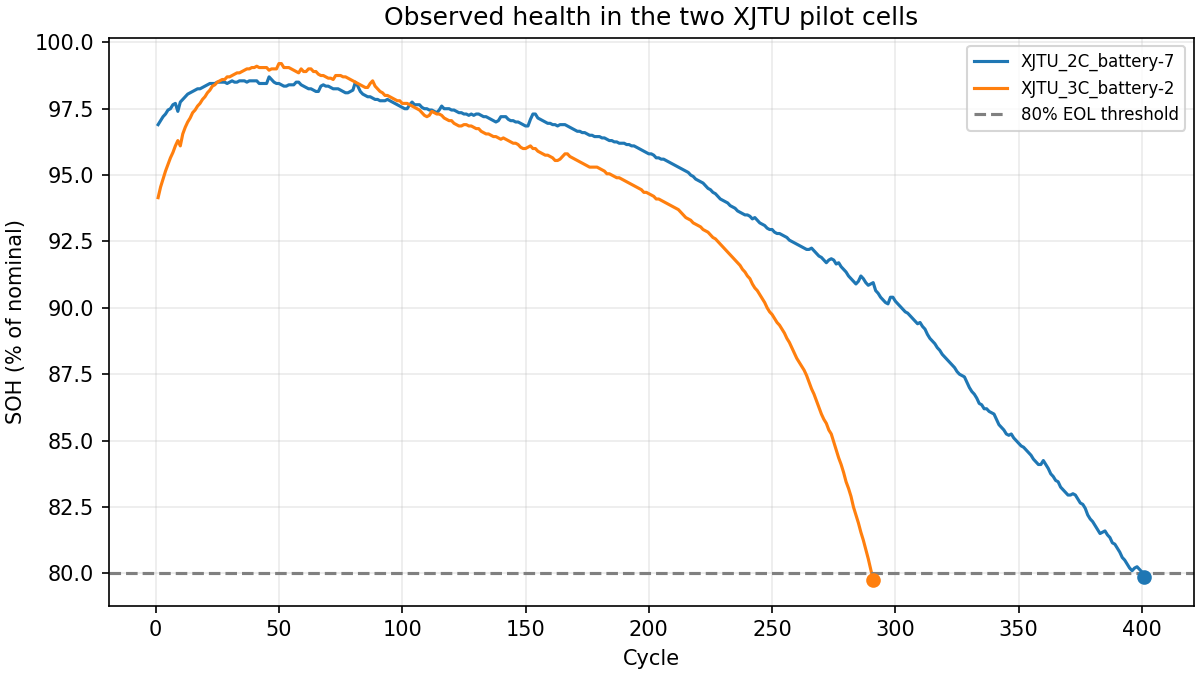

CPU fold 1/5: 18 training cells, 5 held-out cells
CPU fold 2/5: 18 training cells, 5 held-out cells
CPU fold 3/5: 18 training cells, 5 held-out cells
CPU fold 4/5: 19 training cells, 4 held-out cells
CPU fold 5/5: 19 training cells, 4 held-out cells
Results ZIP: /kaggle/working/lifeguard_soh_results.zip


# LifeGuard-RL XJTU SOH results

Mode **benchmark** · 23 cells · 6,937 of 6,938 eligible cycles

SOH uses full discharge capacity divided by the 2.0 Ah nominal capacity. Each prediction uses data available before discharge.

Pilot 80% crossings verified at cycle 401 for the 2C cell and cycle 291 for the 3C cell.

- Excluded **1** cycles with no taper cutoff.

Dual-GPU stage **disabled**.

Lowest observed held-out mean per-cell MAE **hist_gradient_boosting**.

MAE and RMSE are calculated within each held-out cell and then averaged across cells.

| Model | Cells | Cycles | MAE (pp) | RMSE (pp) |
| --- | ---: | ---: | ---: | ---: |
| hist_gradient_boosting | 23 | 6937 | 0.1549 | 0.2555 |
| ridge_charging_features | 23 | 6937 | 0.1931 | 0.3840 |
| ridge_cycle_and_rate | 23 | 6937 | 2.4899 | 3.0332 |
| ridge_cycle_only | 23 | 6937 | 2.7211 | 3.2926 |

The comparison estimates within-collection performance on unseen XJTU cells at the two represented charge rates. Re-evaluate the selected model on an independent collection before claiming broader generalisation.


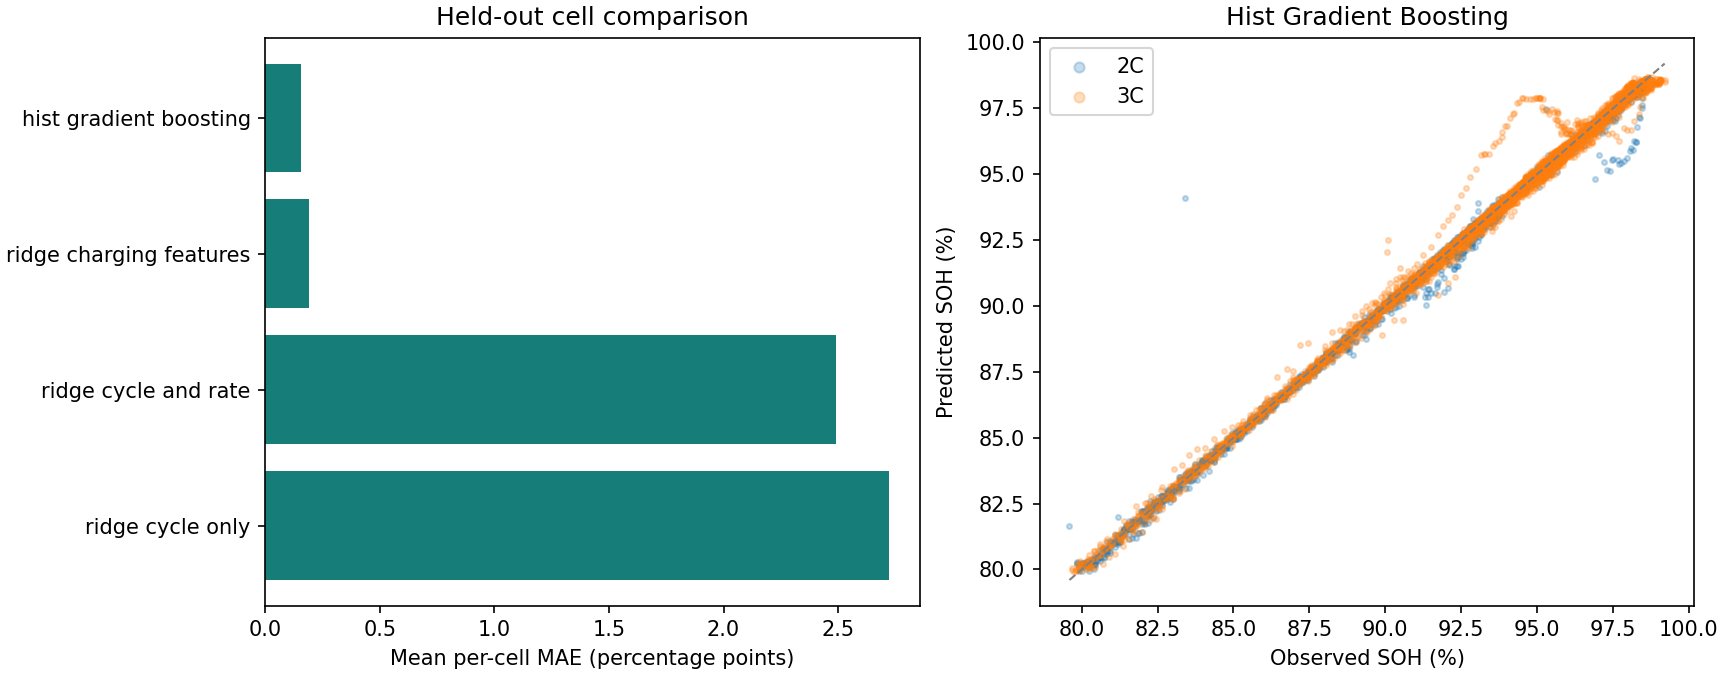

In [27]:
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
metadata = {
    "mode": MODE,
    "seed": SEED,
    "dataset": "BatteryLife v12",
    "dataset_doi": "10.5281/zenodo.21149533",
    "cells": selected_ids,
    "total_cycles": len(quality),
    "eligible_cycles": len(features),
    "pilot_eol_cycles": PILOT_EOLS,
    "gpu_status": "pending" if RUN_DUAL_GPU else "disabled",
    "python": sys.version.split()[0],
    "packages": {package: version(package) for package in ("numpy", "pandas", "scikit-learn", "matplotlib")},
}
with TemporaryDirectory(prefix="lifeguard_soh_", dir=OUTPUT_ROOT) as job_dir:
    work = Path(job_dir)
    result_dir = work / "results"
    result_dir.mkdir()
    quality.to_csv(result_dir / "cycle_quality.csv", index=False)
    features.to_csv(result_dir / "cycle_features.csv", index=False)
    plot_pilot(quality, result_dir / "pilot_soh.png")
    display(Image(filename=str(result_dir / "pilot_soh.png")))

    metrics = None
    if MODE == "benchmark":
        splits, split_table = build_splits(features)
        split_table.to_csv(result_dir / "cell_splits.csv", index=False)
        with threadpool_limits(limits=4):
            predictions, tuning = run_cpu_benchmarks(features, splits)
        tuning.to_csv(result_dir / "cpu_fold_parameters.csv", index=False)
        metrics = export_predictions(result_dir, predictions, features, splits)

    results_zip = publish_results(work, result_dir, OUTPUT_ROOT, metadata, quality, metrics)
    print(f"Results ZIP: {results_zip}")

    if RUN_DUAL_GPU:
        try:
            metadata["packages"]["torch"] = version("torch")
            cnn = run_gpu(work, result_dir, features, charge_curves, splits)
        except Exception as error:
            metadata["gpu_status"] = "failed"
            metadata["gpu_error"] = str(error)
            publish_results(work, result_dir, OUTPUT_ROOT, metadata, quality, metrics)
            raise
        predictions = pd.concat([predictions, cnn], ignore_index=True)
        metrics = export_predictions(result_dir, predictions, features, splits)
        metadata["gpu_status"] = "completed"
        publish_results(work, result_dir, OUTPUT_ROOT, metadata, quality, metrics)

    display(Markdown((result_dir / "summary.md").read_text(encoding="utf-8")))
    if metrics is not None:
        display(Image(filename=str(result_dir / "heldout_predictions.png")))

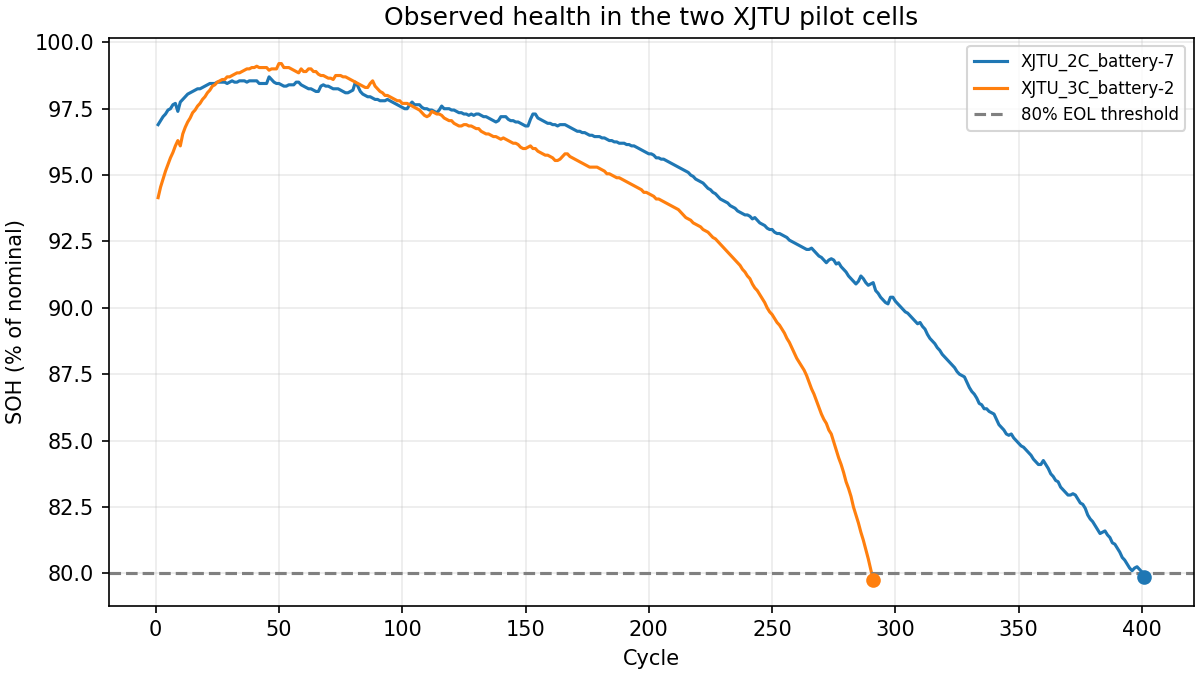

CPU fold 1/5: 18 training cells, 5 held-out cells
CPU fold 2/5: 18 training cells, 5 held-out cells
CPU fold 3/5: 18 training cells, 5 held-out cells
CPU fold 4/5: 19 training cells, 4 held-out cells
CPU fold 5/5: 19 training cells, 4 held-out cells
Results ZIP: /kaggle/working/lifeguard_soh_results.zip


# LifeGuard-RL XJTU SOH results

Mode **benchmark** · 23 cells · 6,937 of 6,938 eligible cycles

SOH uses full discharge capacity divided by the 2.0 Ah nominal capacity. Each prediction uses data available before discharge.

Pilot 80% crossings verified at cycle 401 for the 2C cell and cycle 291 for the 3C cell.

- Excluded **1** cycles with no taper cutoff.

Dual-GPU stage **disabled**.

Lowest observed held-out mean per-cell MAE **hist_gradient_boosting**.

MAE and RMSE are calculated within each held-out cell and then averaged across cells.

| Model | Cells | Cycles | MAE (pp) | RMSE (pp) |
| --- | ---: | ---: | ---: | ---: |
| hist_gradient_boosting | 23 | 6937 | 0.1549 | 0.2555 |
| ridge_charging_features | 23 | 6937 | 0.1931 | 0.3840 |
| ridge_cycle_and_rate | 23 | 6937 | 2.4899 | 3.0332 |
| ridge_cycle_only | 23 | 6937 | 2.7211 | 3.2926 |

The comparison estimates within-collection performance on unseen XJTU cells at the two represented charge rates. Re-evaluate the selected model on an independent collection before claiming broader generalisation.


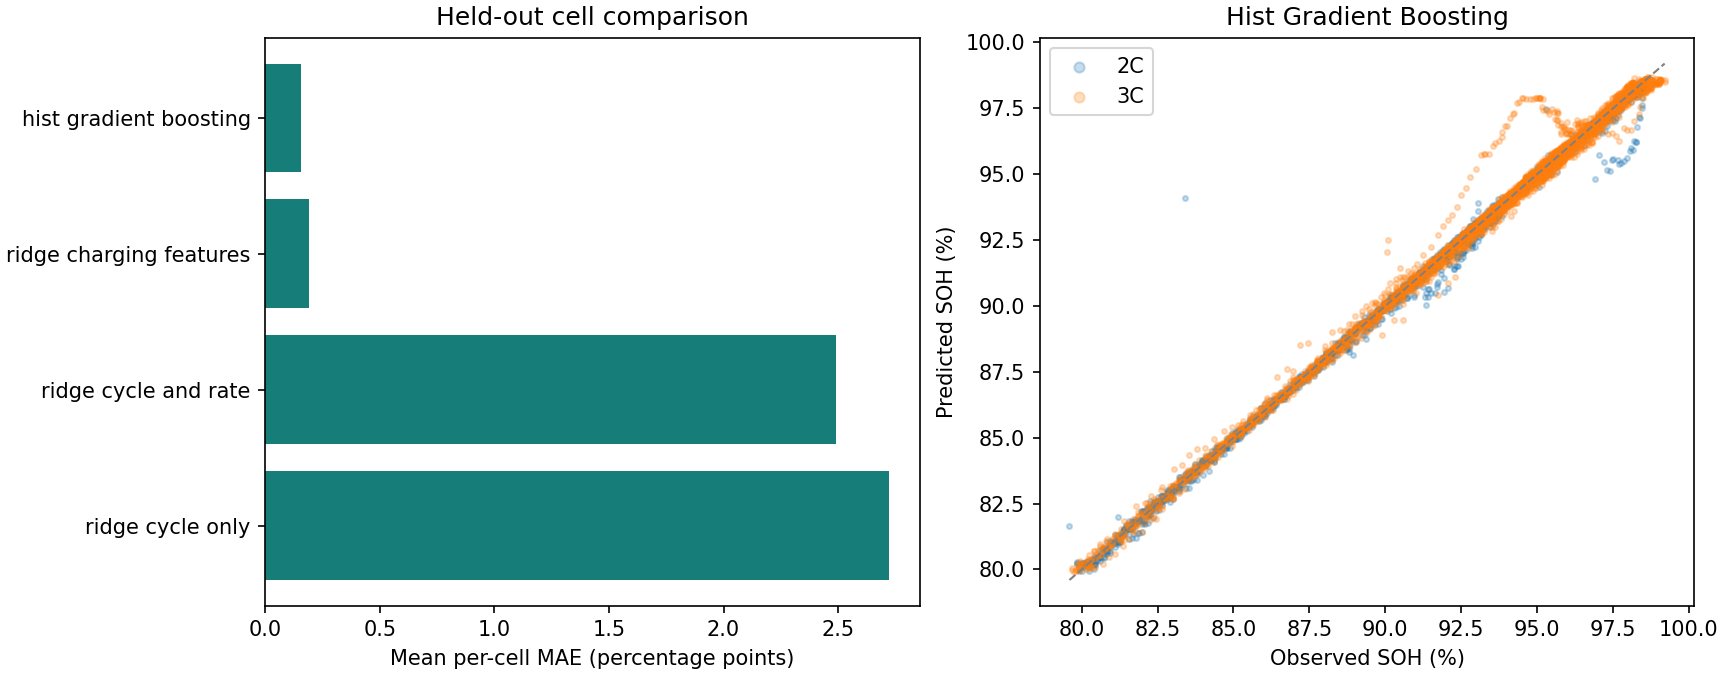

In [28]:
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
metadata = {
    "mode": MODE,
    "seed": SEED,
    "dataset": "BatteryLife v12",
    "dataset_doi": "10.5281/zenodo.21149533",
    "cells": selected_ids,
    "total_cycles": len(quality),
    "eligible_cycles": len(features),
    "pilot_eol_cycles": PILOT_EOLS,
    "gpu_status": "pending" if RUN_DUAL_GPU else "disabled",
    "python": sys.version.split()[0],
    "packages": {package: version(package) for package in ("numpy", "pandas", "scikit-learn", "matplotlib")},
}
with TemporaryDirectory(prefix="lifeguard_soh_", dir=OUTPUT_ROOT) as job_dir:
    work = Path(job_dir)
    result_dir = work / "results"
    result_dir.mkdir()
    quality.to_csv(result_dir / "cycle_quality.csv", index=False)
    features.to_csv(result_dir / "cycle_features.csv", index=False)
    plot_pilot(quality, result_dir / "pilot_soh.png")
    display(Image(filename=str(result_dir / "pilot_soh.png")))

    metrics = None
    if MODE == "benchmark":
        splits, split_table = build_splits(features)
        split_table.to_csv(result_dir / "cell_splits.csv", index=False)
        with threadpool_limits(limits=4):
            predictions, tuning = run_cpu_benchmarks(features, splits)
        tuning.to_csv(result_dir / "cpu_fold_parameters.csv", index=False)
        metrics = export_predictions(result_dir, predictions, features, splits)

    results_zip = publish_results(work, result_dir, OUTPUT_ROOT, metadata, quality, metrics)
    print(f"Results ZIP: {results_zip}")

    if RUN_DUAL_GPU:
        try:
            metadata["packages"]["torch"] = version("torch")
            cnn = run_gpu(work, result_dir, features, charge_curves, splits)
        except Exception as error:
            metadata["gpu_status"] = "failed"
            metadata["gpu_error"] = str(error)
            publish_results(work, result_dir, OUTPUT_ROOT, metadata, quality, metrics)
            raise
        predictions = pd.concat([predictions, cnn], ignore_index=True)
        metrics = export_predictions(result_dir, predictions, features, splits)
        metadata["gpu_status"] = "completed"
        publish_results(work, result_dir, OUTPUT_ROOT, metadata, quality, metrics)

    display(Markdown((result_dir / "summary.md").read_text(encoding="utf-8")))
    if metrics is not None:
        display(Image(filename=str(result_dir / "heldout_predictions.png")))